# Bakas: discharge plume detection from space

**What this does:** pulls free Sentinel-2 satellite imagery from **AWS Open Data**, and uses **OpenCV** to find discharge plumes entering a lake: water that suddenly looks different from the rest of the lake *and* from how the same spot normally looks.

**Why it matters:** PFAS, pharmaceuticals and other emerging contaminants are invisible from space, but they travel with urban and industrial discharge. Plumes show *where* that discharge enters, so costly lab tests go where they count.

**Demo area:** San Juan River mouth, Calamba, Laguna de Bay (Philippines), around the Sept 25, 2026 chemical factory fire at Carmelray Industrial Park.

Run top to bottom: **Runtime > Run all**. No login or GPU needed. Takes about 3 to 5 minutes.

In [1]:
import sys
if "google.colab" in sys.modules:
    !pip -q install pystac-client rasterio

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import cv2
import rasterio
from rasterio.warp import transform_bounds, transform as warp_xy
from rasterio.windows import from_bounds
import matplotlib.pyplot as plt
from pystac_client import Client
from concurrent.futures import ThreadPoolExecutor

print("OpenCV", cv2.__version__)

OpenCV 5.0.0


## 1. Settings

In [3]:
AOI = (121.13, 14.20, 121.26, 14.30)       # area to watch: min_lon, min_lat, max_lon, max_lat
DATE_RANGE = "2026-06-01/2026-10-15"      # dates to search
TARGET_DATE = "2026-09-25"                # the date to check for plumes
MAX_AOI_CLOUD = 30                        # skip scenes with more cloud than this (%) over the AOI

# Detection settings (tuned on Laguna de Bay)
COLOR_THR = 4.0       # how different from the open lake a pixel must be
CHANGE_THR = 3.0      # how different from the same spot on other dates
MIN_HA = 30           # smallest plume to report (hectares)
MIN_CHANGE = 4.5      # a plume's typical change score must reach this
MAX_ROUGH = 1.8       # plumes are smooth; patchy scum / glint is rougher than this
SHORE_KM = 1.0        # a plume must start within this distance of the shore or a river mouth

STAC_URL = "https://earth-search.aws.element84.com/v1"
CLOUD_SCL = [3, 8, 9, 10]   # Sentinel-2 scene classes: cloud shadow, cloud, cirrus

## 2. Find every Sentinel-2 pass over the area

In [4]:
client = Client.open(STAC_URL)
items = sorted(client.search(collections=["sentinel-2-l2a"], bbox=AOI, datetime=DATE_RANGE, max_items=500).items(),
               key=lambda it: it.datetime)

# The AOI can fall on more than one tile; keep the tile that covers it best (most passes)
tiles = {}
for it in items:
    tiles.setdefault(it.properties["s2:mgrs_tile"] if "s2:mgrs_tile" in it.properties else it.id.split("_")[1], []).append(it)
print({t: len(v) for t, v in tiles.items()})

{'51PUR': 33, '51PTR': 33}


## 3. Download only the small AOI window from each scene
Cloud-optimized GeoTIFFs let us read just the box we need instead of the full 110 km tile.

In [5]:
def read_window(href, out_shape=None):
    with rasterio.open(href) as src:
        b = transform_bounds("EPSG:4326", src.crs, *AOI)
        win = from_bounds(*b, transform=src.transform)
        kw = {"window": win}
        if out_shape is not None:
            kw["out_shape"] = (src.count, *out_shape)
        data = src.read(**kw)
        tr = src.window_transform(win)
        if out_shape is not None:
            tr = tr * tr.scale(win.width / out_shape[1], win.height / out_shape[0])
        return data, tr, src.crs


def load_scene(item):
    a = item.assets
    rgb, tr, crs = read_window(a["visual"].href)
    rgb = np.transpose(rgb, (1, 2, 0))
    h, w = rgb.shape[:2]
    # Earth Search already removed the -0.1 offset when this flag is set
    offset = 0.0 if item.properties.get("earthsearch:boa_offset_applied", False) else (
        -0.1 if float(item.properties.get("s2:processing_baseline", "0")) >= 4 else 0.0)
    scene = {"rgb": rgb, "transform": tr, "crs": crs, "date": item.datetime.strftime("%Y-%m-%d"), "id": item.id}
    scene["scl"] = read_window(a["scl"].href, (h, w))[0][0]
    for k in ["blue", "green", "red", "nir", "swir16"]:
        scene[k] = read_window(a[k].href, (h, w))[0][0].astype("float32") * 1e-4 + offset
    scene["aoi_cloud"] = 100 * np.isin(scene["scl"], CLOUD_SCL).mean()
    return scene


# Quick cloud check using only the small SCL layer, then full download for clear scenes
def aoi_cloud(item):
    scl, _, _ = read_window(item.assets["scl"].href)
    return 100 * np.isin(scl[0], CLOUD_SCL).mean()

tile = max(tiles, key=lambda t: len(tiles[t]))
cands = tiles[tile]
with ThreadPoolExecutor(8) as ex:
    clouds = list(ex.map(aoi_cloud, cands))
for it, c in zip(cands, clouds):
    print(f"{it.datetime:%Y-%m-%d}  AOI cloud {c:5.1f}%  {'use' if c <= MAX_AOI_CLOUD else 'skip'}")

clear_items = [it for it, c in zip(cands, clouds) if c <= MAX_AOI_CLOUD]
with ThreadPoolExecutor(6) as ex:
    scenes = list(ex.map(load_scene, clear_items))
scenes = {s["date"]: s for s in scenes}
print("Clear scenes:", list(scenes))
assert TARGET_DATE in scenes, f"{TARGET_DATE} is not clear enough over the AOI, pick another TARGET_DATE"

2026-06-05  AOI cloud 100.0%  skip
2026-06-07  AOI cloud  33.5%  skip
2026-06-10  AOI cloud  77.0%  skip
2026-06-15  AOI cloud  39.2%  skip
2026-06-20  AOI cloud  49.7%  skip
2026-06-25  AOI cloud 100.0%  skip
2026-06-27  AOI cloud 100.0%  skip
2026-06-30  AOI cloud 100.0%  skip
2026-07-05  AOI cloud   0.0%  use
2026-07-10  AOI cloud 100.0%  skip
2026-07-15  AOI cloud 100.0%  skip
2026-07-20  AOI cloud  35.9%  skip
2026-07-25  AOI cloud 100.0%  skip
2026-07-27  AOI cloud 100.0%  skip
2026-07-30  AOI cloud  99.3%  skip
2026-08-04  AOI cloud  53.5%  skip
2026-08-09  AOI cloud 100.0%  skip
2026-08-14  AOI cloud 100.0%  skip
2026-08-16  AOI cloud  82.9%  skip
2026-08-19  AOI cloud 100.0%  skip
2026-08-24  AOI cloud  95.4%  skip
2026-08-29  AOI cloud 100.0%  skip
2026-09-03  AOI cloud  75.1%  skip
2026-09-05  AOI cloud 100.0%  skip
2026-09-08  AOI cloud 100.0%  skip
2026-09-13  AOI cloud   4.4%  use
2026-09-18  AOI cloud   0.2%  use
2026-09-23  AOI cloud  10.1%  use
2026-09-25  AOI cloud   

Clear scenes: ['2026-07-05', '2026-09-13', '2026-09-18', '2026-09-23', '2026-09-25', '2026-10-03']


## 4. OpenCV pipeline

For each scene:
1. **Water mask:** MNDWI (green vs SWIR), because Laguna de Bay is so green with algae that the usual NDWI fails. Morphology cleans it, `connectedComponents` keeps only the lake (drops fishponds).
2. **Color distance:** how far each water pixel's color is from the *open lake* (more than 2 km from shore), using Mahalanobis distance on red/green, blue/green and brightness. Catches both brown sediment and dark organic discharge.
3. **Texture:** local roughness with `cv2.blur`, so sun glint and patchy algae scum are not mistaken for plumes.

Then across dates:

4. **Change vs. baseline:** compare the target date to the median of all other clear dates, so permanently murky shallows are not flagged.
5. **Segmentation:** threshold, morphology, `findContours`, then keep blobs that are big enough, smooth, near the shore, and clearly changed.

In [6]:
def robust_stats(x):
    med = np.median(x); return med, np.median(np.abs(x - med)) * 1.4826 + 1e-6


def smooth_nan(x, sigma=2):
    m = np.isfinite(x).astype("float32"); v = np.nan_to_num(x).astype("float32")
    out = cv2.GaussianBlur(v, (0, 0), sigma) / np.maximum(cv2.GaussianBlur(m, (0, 0), sigma), 1e-3)
    out[m == 0] = np.nan
    return out


def water_mask(s, erode_px=3):
    g, sw = s["green"], s["swir16"]
    mndwi = (g - sw) / (g + sw + 1e-6)
    cloud = np.isin(s["scl"], CLOUD_SCL)
    w = (((mndwi > 0) | (s["scl"] == 6)) & ~cloud).astype(np.uint8) * 255
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    w = cv2.morphologyEx(cv2.morphologyEx(w, cv2.MORPH_OPEN, k), cv2.MORPH_CLOSE, k)
    n, lab, st, _ = cv2.connectedComponentsWithStats(w, 8)
    if n > 1:
        w = np.where(lab == 1 + np.argmax(st[1:, cv2.CC_STAT_AREA]), 255, 0).astype(np.uint8)
    lake = w.copy()
    w = cv2.erode(w, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * erode_px + 1,) * 2))
    return w > 0, lake, cloud


def roughness(x, k=7):
    x = x.astype("float32"); mu = cv2.blur(x, (k, k))
    return np.sqrt(np.clip(cv2.blur(x * x, (k, k)) - mu * mu, 0, None))


def analyze(s):
    wm, lake, cloud = water_mask(s)
    r, g, b = [np.clip(s[k], 1e-3, None) for k in ["red", "green", "blue"]]
    feats = np.stack([np.log(r / g), np.log(b / g), np.log(g)], -1).astype("float32")
    rough = roughness(np.log(g))
    tex = rough > np.percentile(rough[wm], 95)
    shore_dist = cv2.distanceTransform(lake, cv2.DIST_L2, 5)        # pixels (10 m) from land
    ref = wm & ~tex & (shore_dist > 200)                            # open lake, > 2 km offshore
    if ref.sum() < 2000:
        ref = wm & ~tex
    X = feats[ref]; mu = np.median(X, 0)
    inv = np.linalg.inv(np.cov((X - mu).T) + np.eye(3) * 1e-6)
    d = feats - mu
    D = np.sqrt(np.einsum("...i,ij,...j->...", d, inv, d))
    D = smooth_nan(np.where(wm & ~tex, D, np.nan), 2)
    s.update(wm=wm, lake=lake, cloud=cloud, D=D, delta=d, rough=rough, shore_dist=shore_dist,
             rough_ref=np.median(rough[wm]))
    return s


with ThreadPoolExecutor(4) as ex:
    list(ex.map(analyze, scenes.values()))
print("Analyzed", len(scenes), "scenes")

Analyzed 6 scenes


In [7]:
def pixel_to_lonlat(s, x, y):
    X, Y = s["transform"] * (x, y)
    lon, lat = warp_xy(s["crs"], "EPSG:4326", [X], [Y])
    return lon[0], lat[0]


def detect(date):
    s = scenes[date]
    others = [o for o in scenes if o != date]
    base = np.nanmedian(np.stack([scenes[o]["D"] for o in others]), 0)
    chg = s["D"] - base
    m = ((np.nan_to_num(s["D"]) > COLOR_THR) & (np.nan_to_num(chg) > CHANGE_THR)).astype(np.uint8) * 255
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    m = cv2.morphologyEx(cv2.morphologyEx(m, cv2.MORPH_OPEN, k), cv2.MORPH_CLOSE, k)
    near_cloud = cv2.dilate(s["cloud"].astype(np.uint8), np.ones((61, 61), np.uint8)) > 0

    plumes = []
    for c in cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]:
        ha = cv2.contourArea(c) / 100
        if ha < MIN_HA:
            continue
        mm = np.zeros_like(m); cv2.drawContours(mm, [c], -1, 255, -1); mm = mm > 0
        p = dict(contour=c, area_ha=ha,
                 shore_m=float(s["shore_dist"][mm].min() * 10),
                 change=float(np.nanmedian(chg[mm])),
                 rough=float(np.median(s["rough"][mm]) / s["rough_ref"]),
                 near_cloud=float(near_cloud[mm].mean()))
        if p["shore_m"] > SHORE_KM * 1000 or p["change"] < MIN_CHANGE or p["rough"] > MAX_ROUGH or p["near_cloud"] > 0.3:
            continue
        dlt = np.median(s["delta"][mm], 0)            # [ln(r/g), ln(b/g), ln(g)] vs open lake
        brown, dark = dlt[0] > 0.05, dlt[2] < -0.1
        p["kind"] = "brown + dark" if brown and dark else "brown / sediment" if brown else "dark / organic" if dark else "unusual color"
        M = cv2.moments(c); cx, cy = M["m10"] / M["m00"], M["m01"] / M["m00"]
        p["lon"], p["lat"] = pixel_to_lonlat(s, cx, cy)
        # point where the plume touches the shore = likely source
        ys, xs = np.where(mm & (s["shore_dist"] <= s["shore_dist"][mm].min() + 1))
        p["src_lon"], p["src_lat"] = pixel_to_lonlat(s, xs.mean(), ys.mean())
        p["risk"] = "HIGH" if ha >= 200 and p["change"] >= 5 else "MEDIUM"
        plumes.append(p)
    plumes.sort(key=lambda p: -p["area_ha"] * p["change"])
    return plumes, chg


results = {d: detect(d) for d in scenes}
for d, (pl, _) in results.items():
    print(d, f"AOI cloud {scenes[d]['aoi_cloud']:4.0f}%  plumes:", [f"{p['area_ha']:.0f} ha {p['kind']}" for p in pl] or "none")

2026-07-05 AOI cloud    0%  plumes: none
2026-09-13 AOI cloud    4%  plumes: none
2026-09-18 AOI cloud    0%  plumes: none
2026-09-23 AOI cloud   10%  plumes: none
2026-09-25 AOI cloud    0%  plumes: ['806 ha brown + dark']
2026-10-03 AOI cloud   13%  plumes: none


## 5. Target date: what the system flags

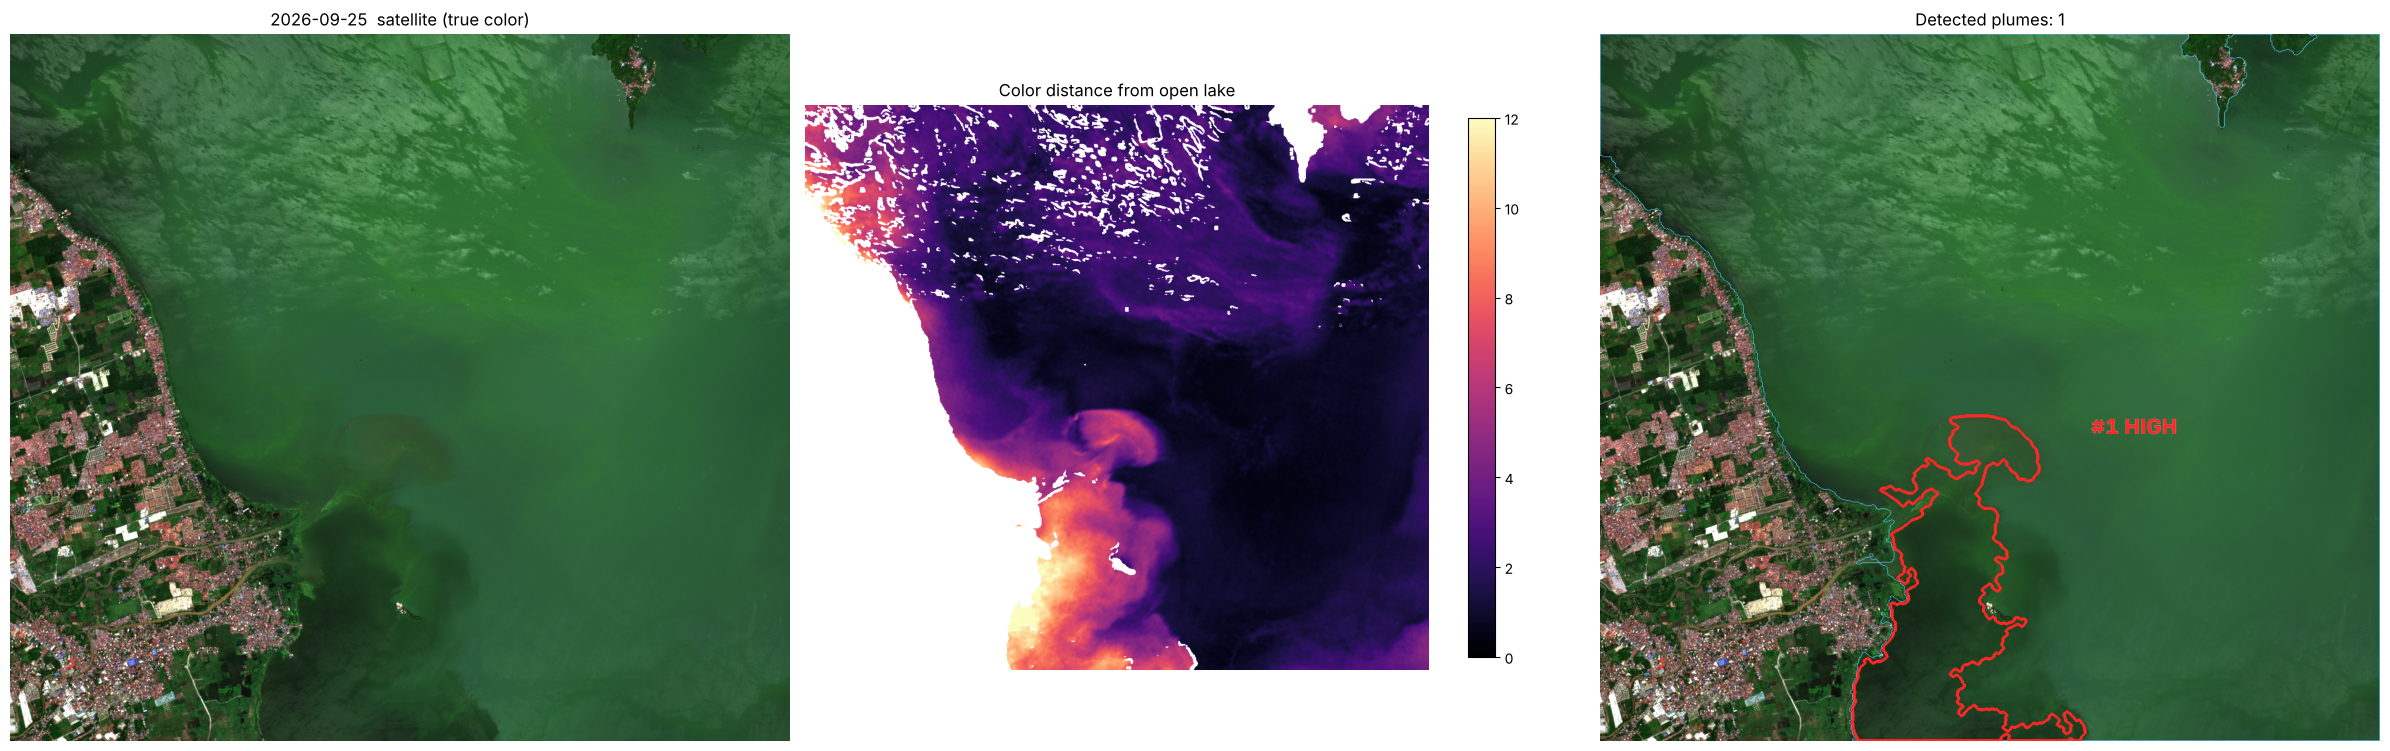

In [8]:
def draw(date, plumes):
    s = scenes[date]; ov = s["rgb"].copy()
    edge = cv2.findContours(s["lake"], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]
    cv2.drawContours(ov, edge, -1, (80, 200, 255), 1)
    for i, p in enumerate(plumes):
        col = (255, 40, 40) if p["risk"] == "HIGH" else (255, 190, 0)
        cv2.drawContours(ov, [p["contour"]], -1, col, 4)
        x, y, w, h = cv2.boundingRect(p["contour"])
        cv2.putText(ov, f"#{i+1} {p['risk']}", (x + w + 8, y + 30), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (255, 255, 255), 6, cv2.LINE_AA)
        cv2.putText(ov, f"#{i+1} {p['risk']}", (x + w + 8, y + 30), cv2.FONT_HERSHEY_SIMPLEX, 1.2, col, 2, cv2.LINE_AA)
    return ov

plumes, chg = results[TARGET_DATE]
s = scenes[TARGET_DATE]
fig, ax = plt.subplots(1, 3, figsize=(24, 8))
ax[0].imshow(s["rgb"]); ax[0].set_title(f"{TARGET_DATE}  satellite (true color)")
im1 = ax[1].imshow(s["D"], cmap="magma", vmin=0, vmax=12); ax[1].set_title("Color distance from open lake")
plt.colorbar(im1, ax=ax[1], shrink=0.7)
ax[2].imshow(draw(TARGET_DATE, plumes)); ax[2].set_title(f"Detected plumes: {len(plumes)}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig("bakas_target.png", dpi=130, bbox_inches="tight"); plt.show()

## 6. Before / after
Every clear date with the same detector. Only the target date should light up if the plume is a real event.

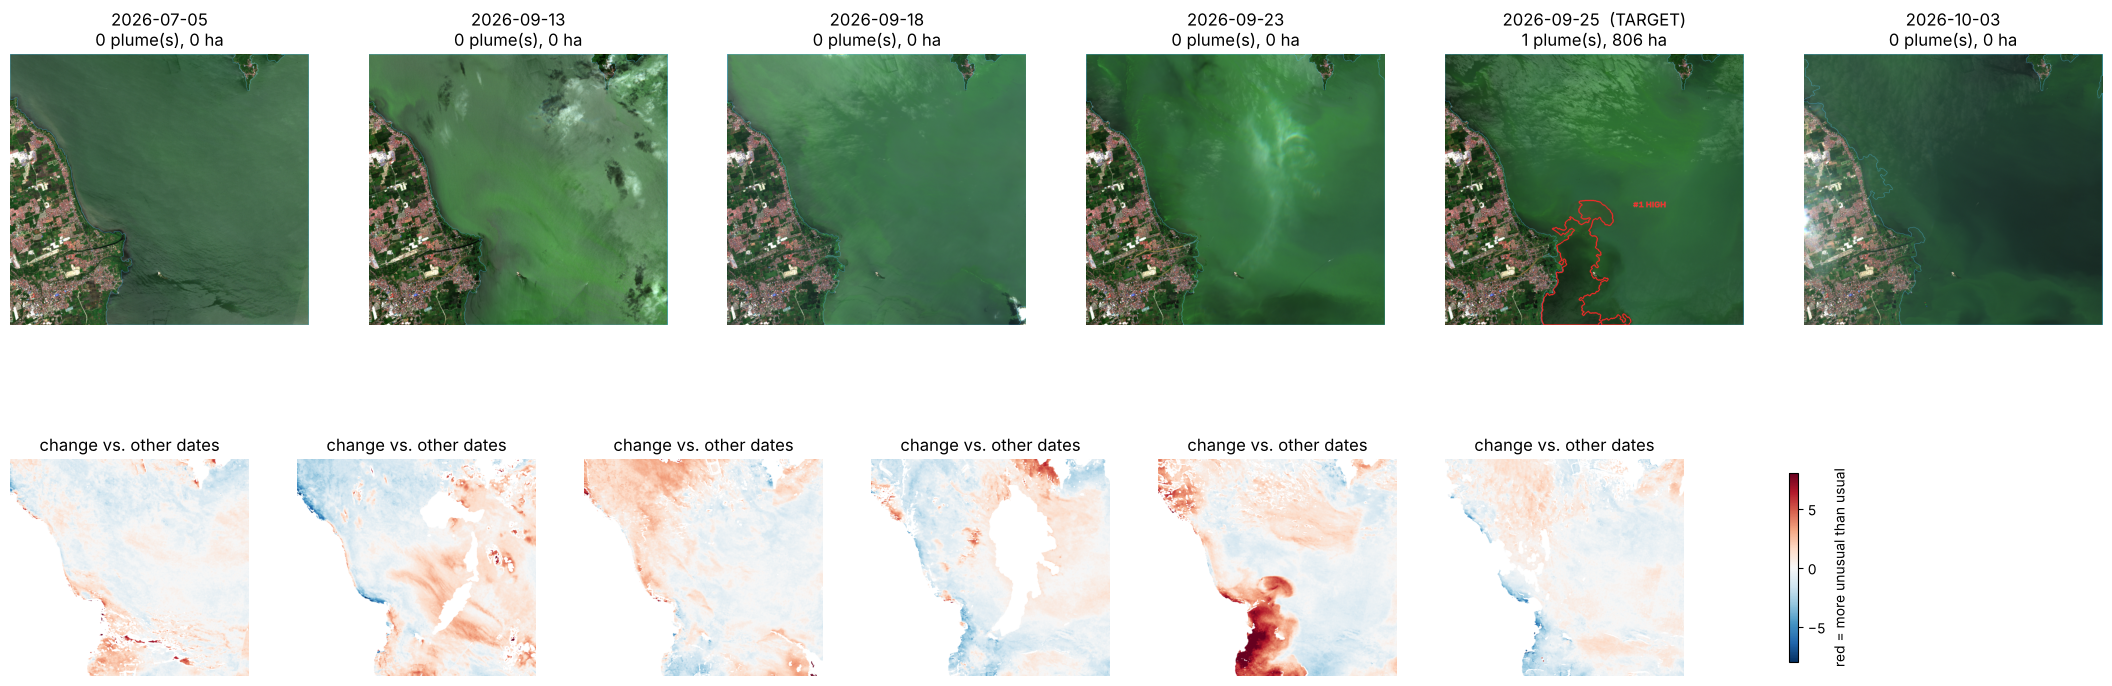

In [9]:
dates = sorted(scenes)
fig, ax = plt.subplots(2, len(dates), figsize=(4.5 * len(dates), 9), squeeze=False)
for i, d in enumerate(dates):
    pl, ch = results[d]
    ax[0, i].imshow(draw(d, pl))
    ax[0, i].set_title(f"{d}{'  (TARGET)' if d == TARGET_DATE else ''}\n{len(pl)} plume(s), {sum(p['area_ha'] for p in pl):.0f} ha")
    im = ax[1, i].imshow(ch, cmap="RdBu_r", vmin=-8, vmax=8); ax[1, i].set_title("change vs. other dates")
for a in ax.flat: a.axis("off")
fig.colorbar(im, ax=ax[1, :].tolist(), shrink=0.6, label="red = more unusual than usual")
plt.savefig("bakas_before_after.png", dpi=110, bbox_inches="tight"); plt.show()

## 7. Monitoring timeline

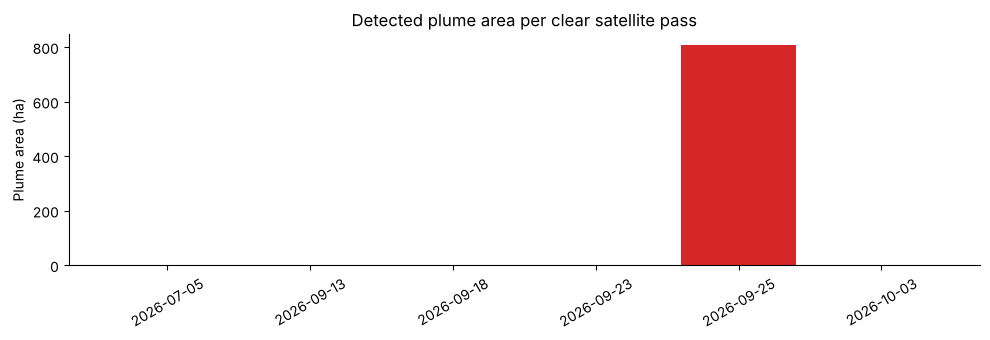

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.5))
areas = [sum(p["area_ha"] for p in results[d][0]) for d in dates]
cols = ["#d62728" if d == TARGET_DATE else "#4c72b0" for d in dates]
ax.bar(dates, areas, color=cols)
ax.set_ylabel("Plume area (ha)"); ax.set_title("Detected plume area per clear satellite pass")
for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
plt.xticks(rotation=30); plt.tight_layout(); plt.savefig("bakas_timeline.png", dpi=130); plt.show()

## 8. Recommended sampling sites
The output an agency acts on: where to send a field team for PFAS / emerging contaminant lab testing.

In [11]:
print(f"Recommended sampling sites for {TARGET_DATE}\n")
for i, p in enumerate(plumes):
    print(f"#{i+1}  {p['risk']:6s}  {p['kind']:16s}  {p['area_ha']:5.0f} ha")
    print(f"     sample plume center : {p['lat']:.5f}, {p['lon']:.5f}   https://maps.google.com/?q={p['lat']:.5f},{p['lon']:.5f}")
    print(f"     likely entry point  : {p['src_lat']:.5f}, {p['src_lon']:.5f}   https://maps.google.com/?q={p['src_lat']:.5f},{p['src_lon']:.5f}\n")
if not plumes:
    print("No significant plume on this date.")

Recommended sampling sites for 2026-09-25

#1  HIGH    brown + dark        806 ha
     sample plume center : 14.21907, 121.18077   https://maps.google.com/?q=14.21907,121.18077
     likely entry point  : 14.21163, 121.17055   https://maps.google.com/?q=14.21163,121.17055



## 9. Download the figures

In [12]:
if "google.colab" in sys.modules:
    from google.colab import files
    for f in ["bakas_target.png", "bakas_before_after.png", "bakas_timeline.png"]:
        files.download(f)

### Notes and limits
- **A plume is a pathway, not proof.** It shows where unusual water enters; only lab tests confirm PFAS or other contaminants.
- **Timing:** Sentinel-2 passes about 10:34 AM local time. Check the fire's start time before linking the Sept 25 plume to it; rain runoff and routine discharge can also cause plumes.
- **Clouds:** rainy-season passes are often unusable. The pipeline skips scenes with more than `MAX_AOI_CLOUD` % cloud over the area.
- **Works anywhere:** change `AOI`, `DATE_RANGE` and `TARGET_DATE` to watch another lake or river mouth.